<a href="https://colab.research.google.com/github/Lekhana-Y/ML/blob/main/DT_img_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import os
import subprocess

uploaded=files.upload()
filename=next(iter(uploaded))

!apt-get -qq update
!apt-get -qq install -y unrar

os.makedirs("/content/dataset",exist_ok=True)

subprocess.run(["unrar","x","-o+","/content/"+filename,"/content/dataset"])

print("Dataset extracted successfully")


In [ ]:
import cv2
import numpy as np

X=[]
y=[]
images=[]
image_names=[]

classes=["notsmoking","smoking"]

for root,dirs,files_list in os.walk("/content/dataset"):
    for file in files_list:
        if file.lower().endswith((".jpg",".jpeg",".png")):
            name=file.lower()

            if "notsmoking" in name:
                label=0
            elif "smoking" in name:
                label=1
            else:
                continue

            path=os.path.join(root,file)

            img=cv2.imread(path)

            if img is not None:
                img=cv2.resize(img,(64,64))
                img_rgb=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

                X.append(cv2.cvtColor(img,cv2.COLOR_BGR2GRAY).flatten())
                y.append(label)
                images.append(img_rgb)
                image_names.append(file)

X=np.array(X)
y=np.array(y)
images=np.array(images)

print("Total images:",len(X))
print("Feature shape:",X.shape)
print("Notsmoking:",np.sum(y==0))
print("Smoking:",np.sum(y==1))

In [ ]:
drop_rows=[10,20,30]

keep=np.ones(len(X),dtype=bool)
keep[drop_rows]=False

X=X[keep]
y=y[keep]
images=images[keep]
image_names=np.array(image_names)[keep]

print("Images after dropping rows:",len(X))

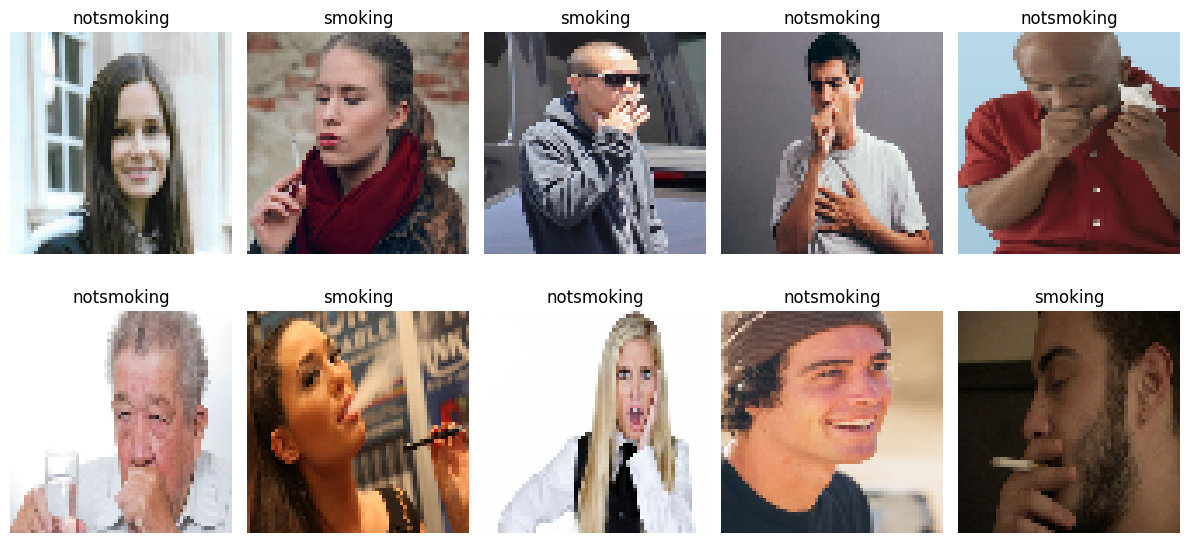

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

for i in range(min(10,len(images))):
    plt.subplot(2,5,i+1)
    plt.imshow(images[i])
    plt.title(classes[y[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test,images_train,images_test,names_train,names_test=train_test_split(
    X,y,images,image_names,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:",len(X_train))
print("Testing images:",len(X_test))

Training images: 176
Testing images: 45


In [ ]:
from sklearn.tree import DecisionTreeClassifier

model=DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

model.fit(X_train,y_train)

y_pred=model.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy=accuracy_score(y_test,y_pred)

print("Accuracy:",accuracy)
print("Accuracy Percentage:",accuracy*100,"%")

Accuracy: 0.5777777777777777
Accuracy Percentage: 57.77777777777777 %


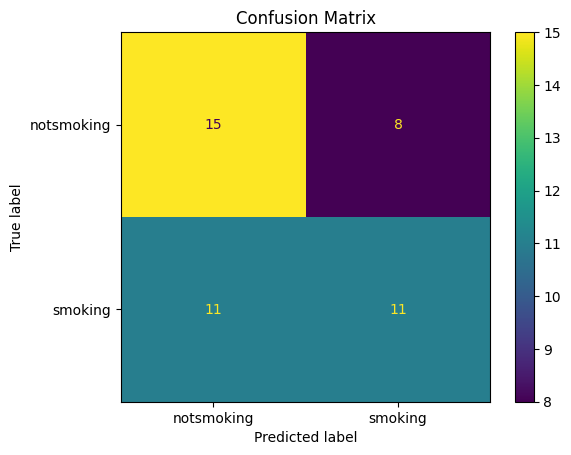

In [ ]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

cm=confusion_matrix(y_test,y_pred)

disp=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

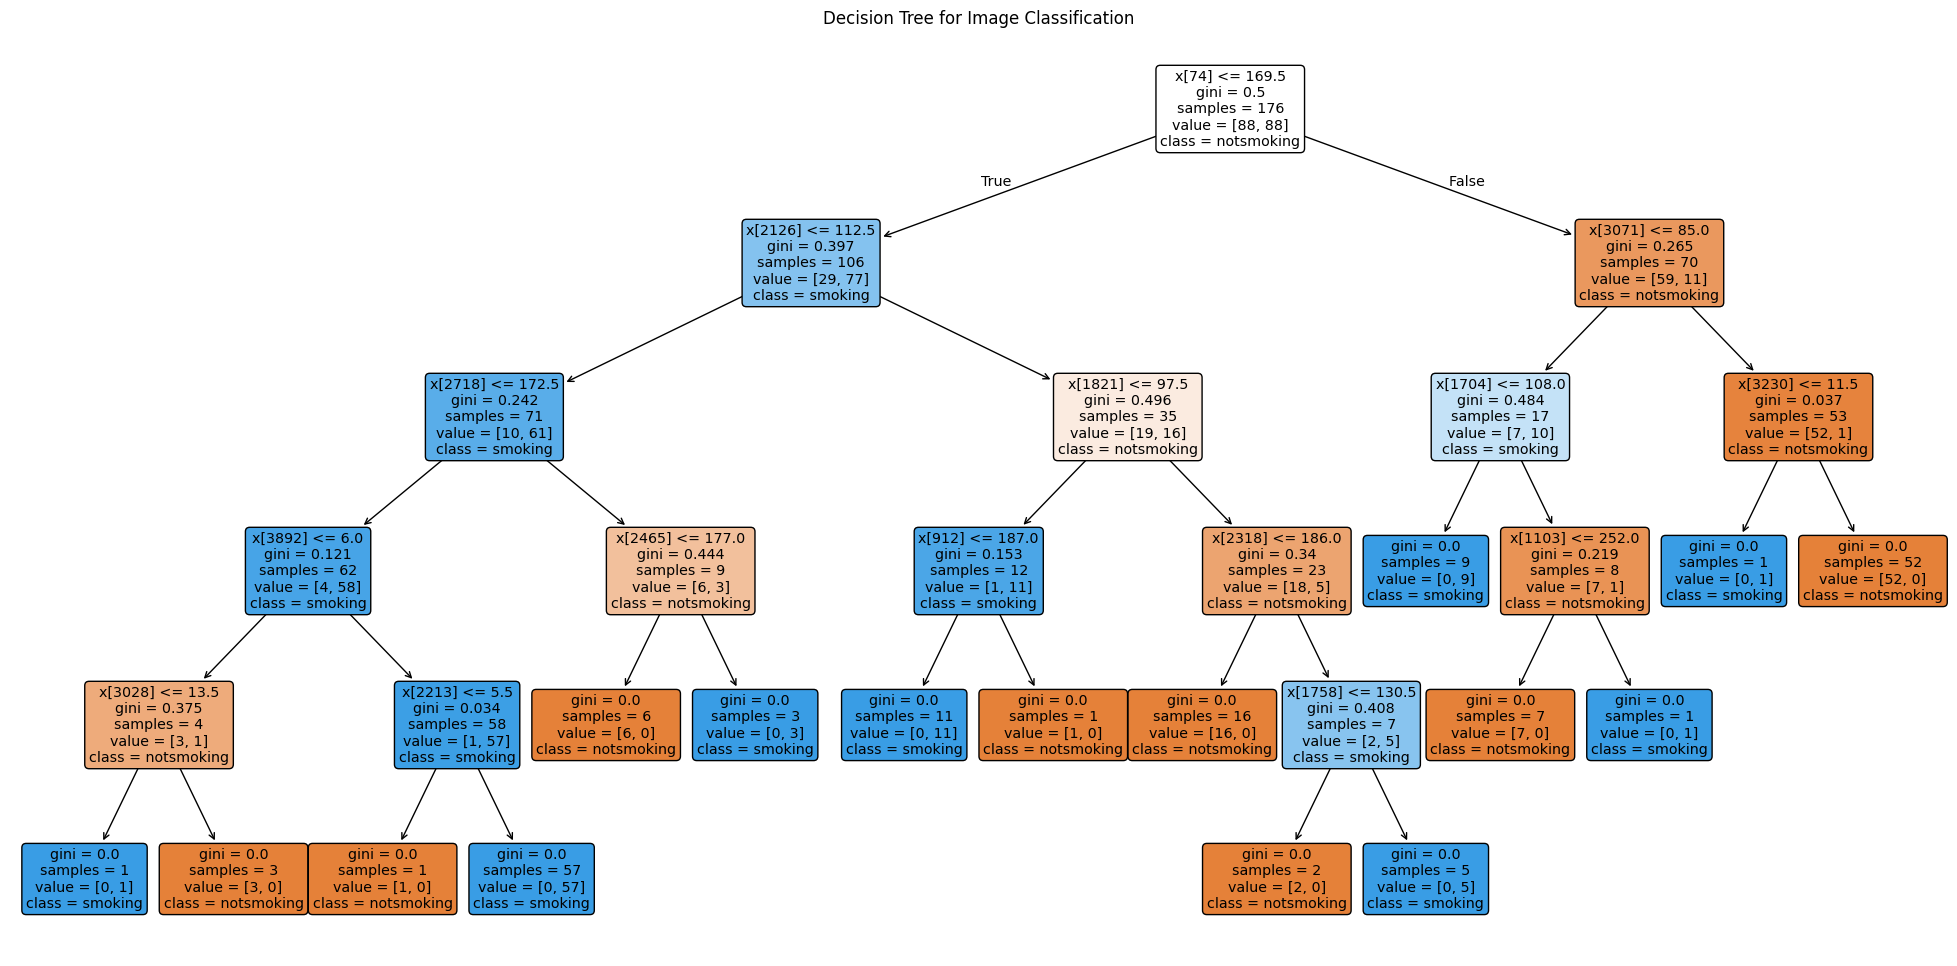

In [ ]:
from sklearn.tree import plot_tree

plt.figure(figsize=(25,12))

plot_tree(
    model,
    class_names=classes,
    filled=True,
    rounded=True,
    max_depth=5
)

plt.title("Decision Tree for Image Classification")
plt.show()